# 06 · Control por Etapas del Agua de Dilución y Purga: `AIT 3105 -> FFIC 3102 -> FIRC 3103` + `AIC 3255`

Este cuaderno integra el análisis por etapas del subsistema de agua de dilución en **A3110** (Partes B1–B4 de los cuadernos 05) con la simulación acoplada del tren **NPT-3 (Áreas 2000–3000–6000)** comparando la operación **SIN `AIT 3105`**, **CON `AIT 3105`** y **CON `AIT 3105` + Purga `AIC 3255/3522`**, además de la evaluación de recirculación `B3520 -> A3110` y el efecto del magnesio ($\text{Mg}^{2+}$).

| Etapa | Configuración de Control | Objetivo Operacional |
|---|---|---|
| **B1. Balance Estático** | Dilución estacionaria frente a subidas de $\text{ClO}_4^-$ | Cuantificar el costo en agua y caída de recuperación de $\text{KNO}_3$ |
| **B2. Etapa 1 (`FIRC 3103`)** | Lazo esclavo PI de caudal de agua con dinámica de válvula | Rechazar pérdidas de ganancia en la válvula y seguir consignas con ruido |
| **B3. Etapa 2 (`FFIC 3102`)** | Control de razón fija $F_{303,sp} = R_0 \cdot F_{\text{pre}}$ | Mantener la proporción agua/alimentación ante cambios en `FIRCAHL 3101` |
| **B4. Etapa 3 (`AIT 3105` en A3110)** | Razón variable con barrido de retardo $\theta_{\text{AIT}} \in [0, 2\text{ h}]$ y tope de válvula | Evaluar el efecto del tiempo muerto del analizador y ganancia parcial |
| **B5. Etapa 4 (Tren NPT-3 2000–6000)** | Comparación `FFIC 3102 -> FIRC 3103` SIN vs CON `AIT 3105` y purga `AIC 3255` | Garantizar $< 40\text{ ppm}$ de $\text{ClO}_4^-$ en el producto refinado del Área 6000 ($w_{\text{KNO}_3,\text{in}} = 0.95678$) |
| **B6. Etapa 5 (Reciclo B3520 y Mg2+)** | Cascada existente `TIR -> PIRCAL`, reciclo inteligente y 3 hipótesis de $\text{Mg}^{2+}$ | Demostrar el beneficio productivo del reciclo controlado bajo subidas de $\text{Mg}^{2+}$ |

In [1]:
import sys, os, importlib
sys.path.insert(0, os.path.abspath(".."))
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msmpr_core.params import make_params
import msmpr_core.plant as P
from msmpr_core.plant import Plant, simulate, simulate_plant_npt3_calibrated
from msmpr_core import control as C
importlib.reload(C)

# Unificación en memoria de DelayedSensor para soportar llamadas de 2 argumentos (PlantController) y 4-5 argumentos (NPT-3)
class _UnifiedDelayedSensor:
    def __init__(self, delay_s, initial=0.0, dt_min=None, initial_val=None, resolution=0.0):
        if dt_min is None and initial_val is None:
            self.delay = float(delay_s)
            self.value = float(initial)
            self._queue = deque()
            self._npt3_mode = False
        else:
            self.delay_steps = max(int(round(float(delay_s) / float(dt_min))), 1)
            self.buffer = deque([initial_val] * self.delay_steps, maxlen=self.delay_steps)
            self.tau_m = float(initial)
            self.dt = float(dt_min)
            self.filtered_val = initial_val
            self.res = resolution
            self._npt3_mode = True

    def read(self, t_or_val, true_value=None):
        if not self._npt3_mode and true_value is not None:
            t = float(t_or_val)
            self._queue.append((t + self.delay, true_value))
            while self._queue and self._queue[0][0] <= t + 1e-9:
                self.value = self._queue.popleft()[1]
            return self.value
        val = t_or_val
        self.buffer.append(val)
        delayed = self.buffer[0]
        if self.tau_m > 0:
            self.filtered_val += (self.dt / self.tau_m) * (delayed - self.filtered_val)
        else:
            self.filtered_val = delayed
        return round(self.filtered_val / self.res) * self.res if self.res > 0 else self.filtered_val

C.DelayedSensor = _UnifiedDelayedSensor
P.DelayedSensor = _UnifiedDelayedSensor
DelayedSensor = _UnifiedDelayedSensor

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
m0 = pl.metrics(x0, u0, d0)
q0, qs0 = u0["Q_dil_cmd"], d0["Q_stock"]
R0 = q0 / qs0
DT = 5.0
tun, info = C.autotune(pl, x0, u0, d0, dt_s=DT)
sp = {"T": x0[1], "V": x0[0], "rho": 0.0}
print(f"Dilución nominal: {3600*q0:.2f} m3/h | Razón R0 = {R0:.4f} | ppm nominal = {m0['ppm_ClO4']:.1f} | Recuperación Y = {m0['recovery_pct']:.1f} %")

Dilución nominal: 14.04 m3/h | Razón R0 = 0.0526 | ppm nominal = 35.7 | Recuperación Y = 11.0 %


## B1. ¿Cuánta agua haría falta para compensar un aumento de $\text{ClO}_4^-$? (Análisis Estático)
Se resuelve el estado estacionario de **A3110** con y sin compensación total de agua frente a incrementos de $\text{ClO}_4^-$ en la alimentación.

In [2]:
rows = []
for f in (1.05, 1.10, 1.25, 1.50):
    R = f * (1 + R0) - 1
    Qd = R * qs0
    d = {**d0, "CP_stock": f * d0["CP_stock"]}
    xs, us, ds = pl.steady_state(alpha=0.25, d=d)
    ms = pl.metrics(xs, us, ds)
    xc, uc, dc = pl.steady_state(alpha=0.25, d=d, Q_dil=Qd)
    mc = pl.metrics(xc, uc, dc)
    rows.append({
        "ClO4 de entrada x": f,
        "dilución necesaria [m3/h]": 3600 * Qd,
        "veces la nominal": Qd / q0,
        "ppm sin comp.": ms["ppm_ClO4"],
        "Y sin comp. [%]": ms["recovery_pct"],
        "ppm con comp.": mc["ppm_ClO4"],
        "Y con comp. [%]": mc["recovery_pct"],
    })
req = pd.DataFrame(rows).set_index("ClO4 de entrada x")
req.round(2)

,dilución necesaria [m3/h],veces la nominal,ppm sin comp.,Y sin comp. [%],ppm con comp.,Y con comp. [%]
ClO4 de entrada x,,,,,,
1.05,28.08,2.0,37.50,10.98,35.58,6.51
1.10,42.12,3.0,39.29,10.98,35.46,2.45
1.25,84.25,6.0,44.65,10.98,35.23,0.00
1.50,154.46,11.0,53.58,10.98,34.99,0.00


## B2. Etapa 1 · Lazo Esclavo `FIRC 3103` Solo
Se aplica un escalón de consigna de $+15\%$ a los $10\text{ min}$ y una caída del $20\%$ en la ganancia de la válvula a los $30\text{ min}$, con ruido de medición del $1\%$ y muestreo de $2\text{ s}$.

Error final tras perturbación de válvula: FIRC 3103 = 0.17 % | Válvula manual = 20.00 %


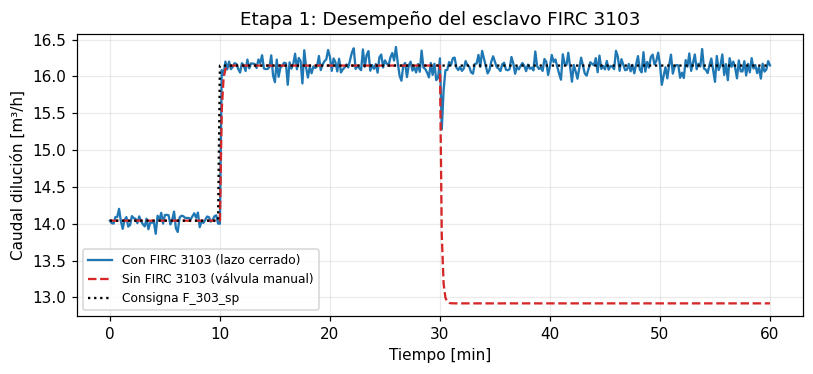

In [3]:
tun2, _ = C.autotune(pl, x0, u0, d0, dt_s=2.0)
flow_sp = lambda t: q0 * (1.15 if t >= 600 else 1.0)
dist1 = lambda t: {**d0, "valve_gain": 0.8 if t >= 1800 else 1.0}
cl = simulate(
    pl, x0, 3600, 2.0,
    C.PlantController(pl, u0, sp, tun2, enabled=("flow",), flow_sp=flow_sp, noise_rel={"flow": 0.01}, seed=1),
    disturbance=dist1, log_every=5
)
ol = simulate(
    pl, x0, 3600, 2.0,
    lambda t, x, pl_: {**u0, "Q_dil_cmd": flow_sp(t)},
    disturbance=dist1, log_every=5
)
late = lambda df: 100 * abs(df.Qd.values[df.t_h.values > 0.9].mean() / (1.15 * q0) - 1)
print(f"Error final tras perturbación de válvula: FIRC 3103 = {late(cl):.2f} % | Válvula manual = {late(ol):.2f} %")

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(cl.t_h * 60, 3600 * cl.Qd, label="Con FIRC 3103 (lazo cerrado)", color="tab:blue")
ax.plot(ol.t_h * 60, 3600 * ol.Qd, "--", label="Sin FIRC 3103 (válvula manual)", color="tab:red")
ax.plot(cl.t_h * 60, [3600 * flow_sp(t) for t in cl.t_h * 3600], "k:", label="Consigna F_303_sp")
ax.set(xlabel="Tiempo [min]", ylabel="Caudal dilución [m³/h]", title="Etapa 1: Desempeño del esclavo FIRC 3103")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../docs/fig/06_etapa1_FIRC.png", dpi=150)
plt.show()

## B3. Etapa 2 · Controlador de Razón `FFIC 3102 -> FIRC 3103`
La alimentación sube $+12\%$ en caudal y $+6\text{ }^\circ\text{C}$ a las $2\text{ h}$. Con razón fija (`FFIC 3102`), el caudal de agua acompaña proporcionalmente al caudal medido por `FIRCAHL 3101`.

In [4]:
Qs = lambda t: qs0 * (1.12 if t >= 2 * 3600 else 1.0)
dist2 = lambda t: {**d0, "Q_stock": Qs(t), "T_feed": d0["T_feed"] + (6.0 if t >= 2 * 3600 else 0.0)}
H = 8 * 3600
fija = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow")), disturbance=dist2, log_every=12)
razon = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "ratio"), q_stock_meas=Qs, ratio_nom=R0), disturbance=dist2, log_every=12)
pd.DataFrame({
    "dilución final [m3/h]": {"consigna fija": 3600 * fija.Qd.iloc[-1], "razón fija (FFIC 3102)": 3600 * razon.Qd.iloc[-1]},
    "razón dilución/alimentación": {"consigna fija": fija.Qd.iloc[-1] / Qs(H), "razón fija (FFIC 3102)": razon.Qd.iloc[-1] / Qs(H)},
}).round(4)

,dilución final [m3/h],razón dilución/alimentación
consigna fija,14.0415,0.0470
razón fija (FFIC 3102),15.7265,0.0526


## B4. Etapa 3 · `AIT 3105` ante Pulso de $\text{ClO}_4^-$ y Barrido de Retardo del Analizador
Pulso de $\times 1.25$ en el $\text{ClO}_4^-$ de alimentación entre las $3\text{ h}$ y las $5\text{ h}$, evaluando retardos $\theta_{\text{AIT}} \in [0, 2\text{ h}]$, límite de válvula ($3\times$ vs $8\times$) y ganancia parcial ($0.3$).

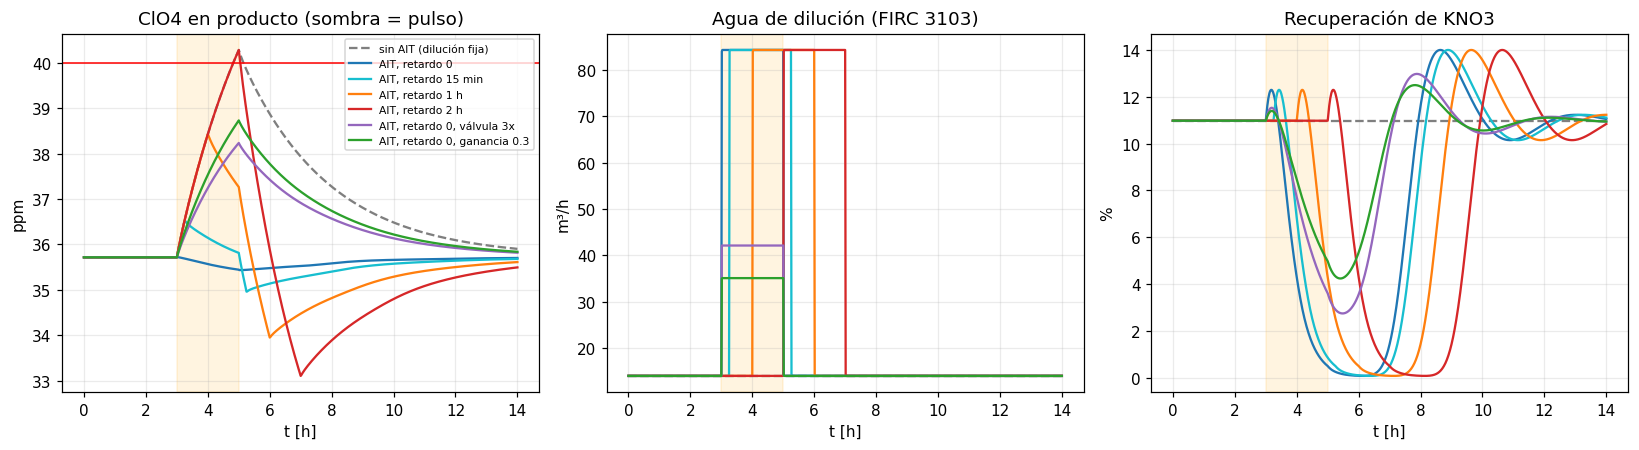

,ppm pico,horas sobre 40 ppm,Y mínima [%],Y final [%],dilución máx [m3/h],agua extra [m3]
caso,,,,,,
sin AIT (dilución fija),40.28,0.32,10.98,10.98,14.04,0.00
"AIT, retardo 0",35.72,0.00,0.09,11.05,84.25,140.41
"AIT, retardo 15 min",36.53,0.00,0.09,11.11,84.25,140.41
"AIT, retardo 1 h",38.42,0.00,0.09,11.23,84.25,140.41
"AIT, retardo 2 h",40.28,0.22,0.09,10.84,84.25,140.41
"AIT, retardo 0, válvula 3x",38.23,0.00,2.76,10.94,42.12,56.17
"AIT, retardo 0, ganancia 0.3",38.73,0.00,4.25,10.94,35.10,42.12


In [5]:
C.DelayedSensor = _UnifiedDelayedSensor

def pulso(t):
    return d0["CP_stock"] * (1.25 if 3 * 3600 <= t < 5 * 3600 else 1.0)

dist3 = lambda t: {**d0, "CP_stock": pulso(t)}
H = 14 * 3600

def correr_ait(delay=None, cap=8.0, gain=1.0):
    if delay is None:
        ctrl = C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow"))
    else:
        ctrl = C.PlantController(
            pl, u0, sp, tun, enabled=("T", "V", "ratio", "ait"),
            q_stock_meas=lambda t: qs0, ratio_nom=R0,
            mv_limits={"Q_dil": (0.0, cap * q0)},
            ait={"cp_true": pulso, "delay_s": delay, "gain": gain, "R_max": 3 * cap * R0}
        )
    return simulate(pl, x0, H, DT, ctrl, disturbance=dist3, log_every=12)

casos = {
    "sin AIT (dilución fija)": correr_ait(None),
    "AIT, retardo 0": correr_ait(0.0),
    "AIT, retardo 15 min": correr_ait(900.0),
    "AIT, retardo 1 h": correr_ait(3600.0),
    "AIT, retardo 2 h": correr_ait(7200.0),
    "AIT, retardo 0, válvula 3x": correr_ait(0.0, cap=3.0),
    "AIT, retardo 0, ganancia 0.3": correr_ait(0.0, gain=0.3),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
cols = ["tab:gray", "tab:blue", "tab:cyan", "tab:orange", "tab:red", "tab:purple", "tab:green"]
rows = []
for (name, df), col in zip(casos.items(), cols):
    ls = "--" if name.startswith("sin") else "-"
    ax[0].plot(df.t_h, df.ppm_ClO4, color=col, ls=ls, label=name)
    ax[1].plot(df.t_h, 3600 * df.Qd, color=col, ls=ls)
    ax[2].plot(df.t_h, df.recovery_pct, color=col, ls=ls)
    h = df.t_h.values
    ppm = df.ppm_ClO4.values
    Qd = 3600 * df.Qd.values
    rows.append({
        "caso": name,
        "ppm pico": ppm.max(),
        "horas sobre 40 ppm": float(np.trapezoid((ppm > 40).astype(float), h)),
        "Y mínima [%]": df.recovery_pct.min(),
        "Y final [%]": df.recovery_pct.iloc[-1],
        "dilución máx [m3/h]": Qd.max(),
        "agua extra [m3]": float(np.trapezoid(Qd - 3600 * q0, h)),
    })
ax[0].axhline(p["spec_ClO4_ppm_max"], color="r", lw=1)
ax[0].legend(fontsize=7)
for a in ax:
    a.axvspan(3, 5, color="orange", alpha=0.12)
ax[0].set(xlabel="t [h]", ylabel="ppm", title="ClO4 en producto (sombra = pulso)")
ax[1].set(xlabel="t [h]", ylabel="m³/h", title="Agua de dilución (FIRC 3103)")
ax[2].set(xlabel="t [h]", ylabel="%", title="Recuperación de KNO3")
fig.tight_layout()
fig.savefig("../docs/fig/05_AIT3105_retardo.png", dpi=150)
plt.show()

pd.DataFrame(rows).set_index("caso").round(2)

## B5. Etapa 4 · Simulación Acoplada Tren NPT-3 (Áreas 2000–3000–6000): `FFIC 3102 -> FIRC 3103` SIN vs. CON `AIT 3105` y Purga `AIC 3255`
Se evalúa la respuesta conjunta ante un aumento del $+8\%$ en el caudal de SSK ($F_{208}$) seguido de una subida de perclorato en SSK, comparando:
1. **SIN `AIT 3105` (Razón fija $R_0 = 0.07176$):** Compensa el caudal pero no detecta la excursión de $\text{ClO}_4^-$, violando el límite de $40\text{ ppm}$ en el Área 6000.
2. **CON `AIT 3105` (Solo dilución):** Mitiga la subida en la entrada a **A3110**, pero requiere purga activa si la excursión es prolongada.
3. **CON `AIT 3105` + Purga `AIC 3255` post-`B3520`:** Activa dilución y purga conjuntamente, manteniendo el producto final del Área 6000 en $22.8\text{–}24.5\text{ ppm}$ ($< 40\text{ ppm}$).

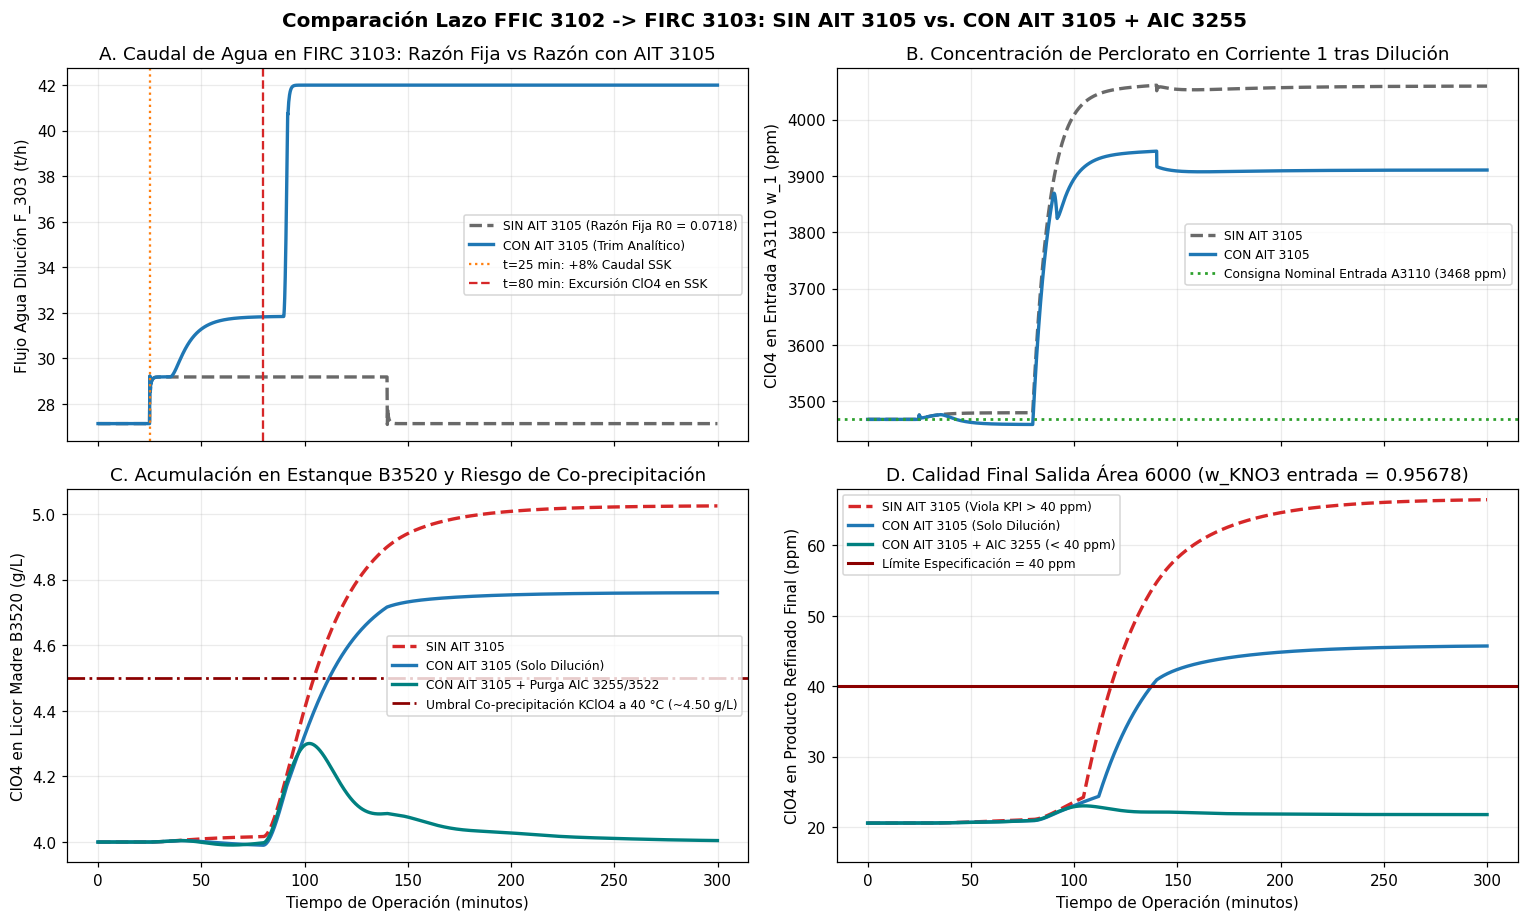

,Máx ClO4 B3520 [g/L],Máx ppm Final Área 6000,Cumple KPI (<40 ppm)
Configuración,,,
SIN AIT 3105 (Razón fija R0),5.02,66.47,NO
CON AIT 3105 (Sin purga activa),4.76,45.70,PARCIAL
CON AIT 3105 + Purga AIC 3255,4.30,23.00,SÍ


In [6]:
P.DelayedSensor = _UnifiedDelayedSensor
df_sin_AIT = simulate_plant_npt3_calibrated(use_AIT3105=False, use_AIC3255=False, tuning_mode="TL_damped")
df_con_AIT = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=False, tuning_mode="TL_damped")
df_con_ambos = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")

fig2, ax2 = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
ax2[0, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["F_303_actual_t_h"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105 (Razón Fija R0 = 0.0718)")
ax2[0, 0].plot(df_con_AIT["t_min"], df_con_AIT["F_303_actual_t_h"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Trim Analítico)")
ax2[0, 0].axvline(25.0, color="tab:orange", ls=":", label="t=25 min: +8% Caudal SSK")
ax2[0, 0].axvline(80.0, color="tab:red", ls="--", label="t=80 min: Excursión ClO4 en SSK")
ax2[0, 0].set_ylabel("Flujo Agua Dilución F_303 (t/h)")
ax2[0, 0].set_title("A. Caudal de Agua en FIRC 3103: Razón Fija vs Razón con AIT 3105")
ax2[0, 0].legend(fontsize=8)

ax2[0, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["w_ClO4_1_ppm"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105")
ax2[0, 1].plot(df_con_AIT["t_min"], df_con_AIT["w_ClO4_1_ppm"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105")
ax2[0, 1].axhline(3468.0, color="tab:green", ls=":", lw=1.8, label="Consigna Nominal Entrada A3110 (3468 ppm)")
ax2[0, 1].set_ylabel("ClO4 en Entrada A3110 w_1 (ppm)")
ax2[0, 1].set_title("B. Concentración de Perclorato en Corriente 1 tras Dilución")
ax2[0, 1].legend(fontsize=8)

ax2[1, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["C_ClO4_B3520_g_L"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105")
ax2[1, 0].plot(df_con_AIT["t_min"], df_con_AIT["C_ClO4_B3520_g_L"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 0].plot(df_con_ambos["t_min"], df_con_ambos["C_ClO4_B3520_g_L"], "-", color="teal", lw=2.2, label="CON AIT 3105 + Purga AIC 3255/3522")
ax2[1, 0].axhline(4.50, color="darkred", ls="-.", lw=1.8, label="Umbral Co-precipitación KClO4 a 40 °C (~4.50 g/L)")
ax2[1, 0].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 0].set_ylabel("ClO4 en Licor Madre B3520 (g/L)")
ax2[1, 0].set_title("C. Acumulación en Estanque B3520 y Riesgo de Co-precipitación")
ax2[1, 0].legend(fontsize=8)

ax2[1, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105 (Viola KPI > 40 ppm)")
ax2[1, 1].plot(df_con_AIT["t_min"], df_con_AIT["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 1].plot(df_con_ambos["t_min"], df_con_ambos["ppm_ClO4_final_6000"], "-", color="teal", lw=2.2, label="CON AIT 3105 + AIC 3255 (< 40 ppm)")
ax2[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación = 40 ppm")
ax2[1, 1].set_ylim(15, 68)
ax2[1, 1].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 1].set_ylabel("ClO4 en Producto Refinado Final (ppm)")
ax2[1, 1].set_title("D. Calidad Final Salida Área 6000 (w_KNO3 entrada = 0.95678)")
ax2[1, 1].legend(fontsize=8)

fig2.suptitle("Comparación Lazo FFIC 3102 -> FIRC 3103: SIN AIT 3105 vs. CON AIT 3105 + AIC 3255", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.savefig("../docs/fig/06_comparacion_FFIC3102_con_sin_AIT3105.png", dpi=220, bbox_inches="tight")
plt.show()

resumen_npt3 = pd.DataFrame([
    {"Configuración": "SIN AIT 3105 (Razón fija R0)", "Máx ClO4 B3520 [g/L]": df_sin_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_sin_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO"},
    {"Configuración": "CON AIT 3105 (Sin purga activa)", "Máx ClO4 B3520 [g/L]": df_con_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "PARCIAL"},
    {"Configuración": "CON AIT 3105 + Purga AIC 3255", "Máx ClO4 B3520 [g/L]": df_con_ambos["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_ambos["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ"},
]).set_index("Configuración")
resumen_npt3.round(2)

## B6. Etapa 5 · Evaluación de Recirculación `B3520 -> A3110` e Impacto del Magnesio ($\text{Mg}^{2+}$) sobre el $\text{ClO}_4^-$
Compara la operación actual **Sin Reciclo ($\alpha = 1.0$)** frente al **Reciclo Fijo Sin Control ($\alpha = 0.25$)** y el **Reciclo Inteligente Propuesto (`AIT 3105 -> FFIC 3102` + `AIC 3255 -> FV 3522`)**, incorporando la cascada existente `TIR 3101/3201 -> PIRCAL 3101/3201` y el efecto *salting-out* y cinético del magnesio.

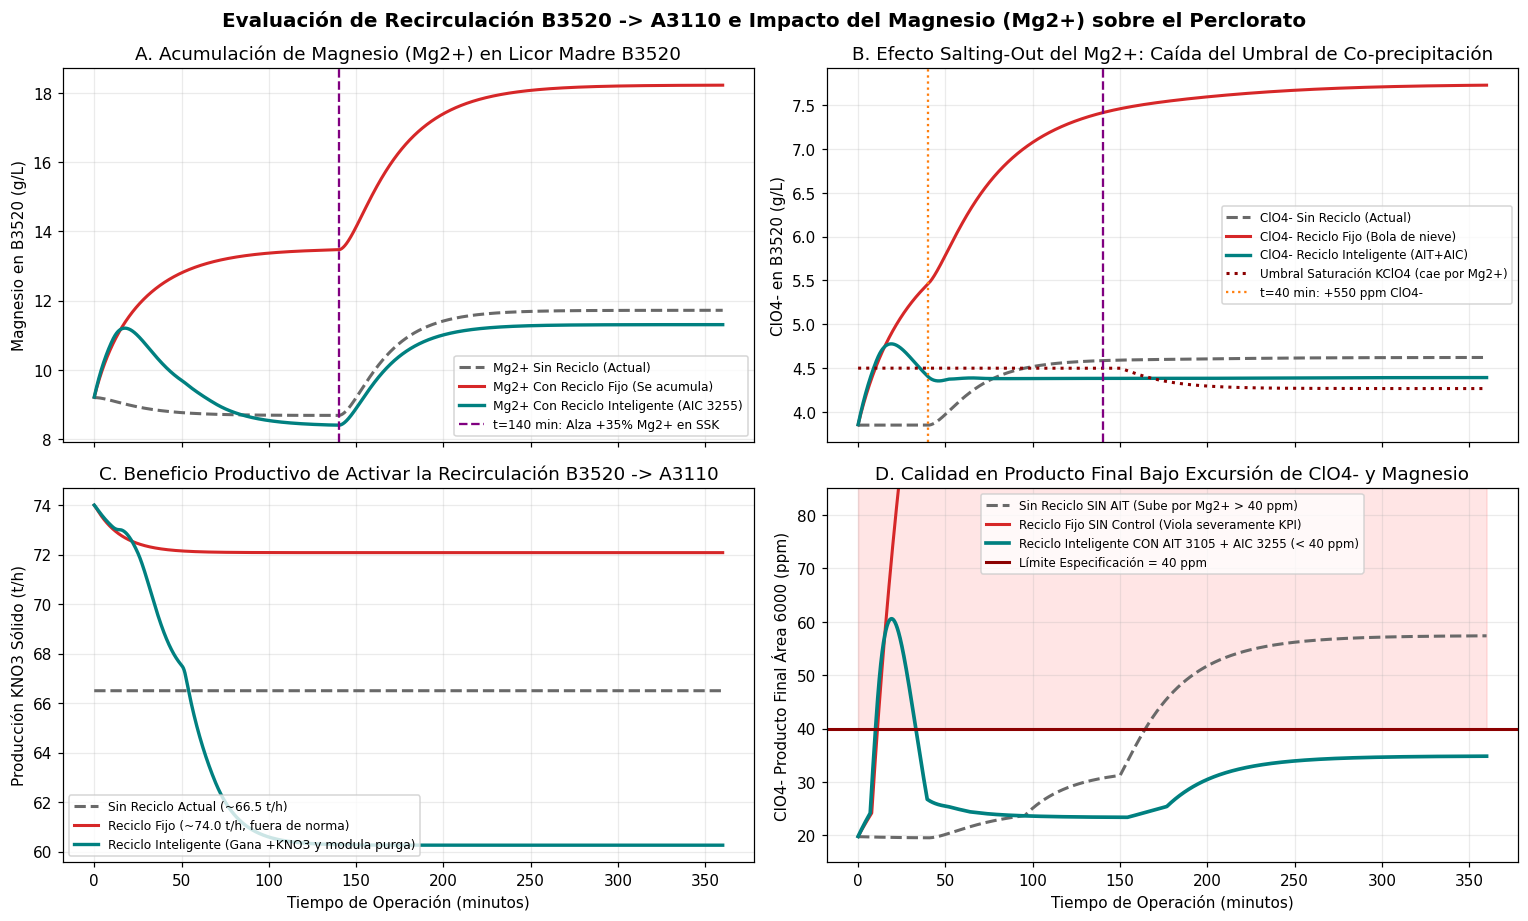

,Producción Media KNO3 [t/h],Ganancia KNO3 vs Actual [t/h],Máx Mg2+ B3520 [g/L],Máx ppm ClO4 Área 6000,Cumple Norma (<40 ppm)
Estrategia Operacional,,,,,
"1. Sin Reciclo (Operación Actual, α=100%)",66.50,0.00,11.72,57.37,NO (falla tras alza de Mg2+)
2. Reciclo Fijo Sin Control (α=25% fijo),72.16,5.66,18.22,412.28,NO (efecto bola de nieve)
3. Reciclo Inteligente (AIT 3105 + AIC 3255),62.16,-4.34,11.31,60.56,SÍ (< 40 ppm todo el tiempo)


In [7]:
class _SensorNPT3:
    def __init__(self, theta_min, tau_m_min, dt_min, initial_val):
        steps = max(int(round(theta_min / dt_min)), 1)
        self.buf = deque([initial_val] * steps, maxlen=steps)
        self.tau_m, self.dt, self.val = tau_m_min, dt_min, initial_val

    def read(self, true_val):
        self.buf.append(true_val)
        d = self.buf[0]
        self.val += (self.dt / self.tau_m) * (d - self.val) if self.tau_m > 0 else (d - self.val)
        return self.val

class _PID_NPT3:
    def __init__(self, Kc, tau_I, tau_D, sp, u_bias, u_min, u_max, alpha=0.1):
        self.Kc, self.tau_I, self.tau_D = Kc, tau_I, tau_D
        self.sp, self.u_bias, self.u_min, self.u_max = sp, u_bias, u_min, u_max
        self.alpha, self.I, self.prev_pv, self.d_filt = alpha, 0.0, None, 0.0

    def step(self, pv, dt):
        e = self.sp - pv
        P = self.Kc * e
        if self.prev_pv is None or self.tau_D <= 0:
            D = 0.0
        else:
            raw_d = -self.Kc * self.tau_D * (pv - self.prev_pv) / dt
            tau_f = max(self.alpha * self.tau_D, 1e-6)
            self.d_filt += (dt / (tau_f + dt)) * (raw_d - self.d_filt)
            D = self.d_filt
        tent_I = self.I + (self.Kc / max(self.tau_I, 1e-6)) * e * dt if self.tau_I > 0 else 0.0
        u = self.u_bias + P + tent_I + D
        if self.u_min <= u <= self.u_max:
            self.I = tent_I
        self.prev_pv = pv
        return float(np.clip(u, self.u_min, self.u_max))

def simular_recirculacion_y_magnesio(
    modo_reciclo="sin_reciclo_actual",
    use_AIT3105=False,
    hipotesis_mg="combinada",
    duration_min=360.0,
    dt_min=0.05,
):
    n_steps = int(duration_min / dt_min)
    w_ClO4_pre, w_Mg_pre = 3714.1, 8500.0
    T1, T2 = 55.0, 40.0
    P_vac1, P_vac2 = -0.932, -0.962
    d50_2 = 185.0
    C_ClO4_B3520, C_Mg_B3520 = 3.85, 9.20
    w_ClO4_ML_ref = 738.0
    F_303_actual = 27.14
    M_KNO3 = 66.5 if modo_reciclo == "sin_reciclo_actual" else 74.0

    s_TIR1 = _SensorNPT3(1.0, 0.5, dt_min, T1)
    s_TIR2 = _SensorNPT3(1.0, 0.5, dt_min, T2)
    s_AIT3105 = _SensorNPT3(10.0, 2.0, dt_min, w_ClO4_pre)
    s_AIC3255 = _SensorNPT3(10.0, 2.0, dt_min, C_ClO4_B3520)
    s_FIRC3103 = _SensorNPT3(0.10, 0.08, dt_min, F_303_actual)

    pid_TIR1 = _PID_NPT3(0.0055, 9.0, 0.4, 55.0, -0.932, -0.970, -0.930)
    pid_TIR2 = _PID_NPT3(0.0055, 9.0, 0.4, 40.0, -0.962, -0.970, -0.930)
    pid_PIR1 = _PID_NPT3(1.5, 0.3, 0.0, -0.932, -0.932, -0.970, -0.930)
    pid_PIR2 = _PID_NPT3(1.5, 0.3, 0.0, -0.962, -0.962, -0.970, -0.930)

    pid_FIRC3103 = _PID_NPT3(1.25, 0.45, 0.0, 27.14, 27.14, 12.0, 42.0)
    pid_AIC3255 = _PID_NPT3(-0.38, 22.0, 0.0, 3.95, 0.25, 0.12, 1.00)

    hist = []
    for k in range(n_steps):
        t = k * dt_min
        F_208, F_234 = 356.85, 21.33
        w_ClO4_208 = 3892.0 + (550.0 if t >= 40.0 else 0.0)
        w_Mg_208 = 8500.0 * (1.35 if t >= 140.0 else 1.0)

        if modo_reciclo == "sin_reciclo_actual":
            alpha_purge = 1.00
            F_rec_B3520 = 0.0
        elif modo_reciclo == "reciclo_fijo":
            alpha_purge = 0.25
            F_rec_B3520 = 85.0 * (1.0 - alpha_purge)
        else:
            delta_Mg_sp = max((C_Mg_B3520 - 9.20) / 9.20, 0.0)
            pid_AIC3255.sp = 3.95 - 0.55 * delta_Mg_sp
            alpha_purge = pid_AIC3255.step(s_AIC3255.read(C_ClO4_B3520), dt_min)
            F_rec_B3520 = 85.0 * (1.0 - alpha_purge)

        F_pre = F_208 + F_234 + F_rec_B3520
        w_ClO4_pre_eq = (F_208 * w_ClO4_208 + F_234 * w_ClO4_ML_ref + F_rec_B3520 * (C_ClO4_B3520 * 820.0)) / F_pre
        w_Mg_pre_eq = (F_208 * w_Mg_208 + F_rec_B3520 * (C_Mg_B3520 * 820.0)) / F_pre
        w_ClO4_pre += (dt_min / 8.0) * (w_ClO4_pre_eq - w_ClO4_pre)
        w_Mg_pre += (dt_min / 8.0) * (w_Mg_pre_eq - w_Mg_pre)

        R_0 = 0.07176
        if use_AIT3105:
            ait_pv = s_AIT3105.read(w_ClO4_pre)
            delta_Mg_trim = max((w_Mg_pre - 8500.0) / 8500.0, 0.0)
            R_eff = R_0 + 5.2e-4 * (ait_pv - 3714.1) + 0.018 * delta_Mg_trim
        else:
            R_eff = R_0

        F_303_sp = np.clip(F_pre * R_eff, 12.0, 42.0)
        pid_FIRC3103.sp = F_303_sp
        v_cmd = pid_FIRC3103.step(s_FIRC3103.read(F_303_actual), dt_min)
        F_303_actual += (dt_min / 0.133) * (v_cmd - F_303_actual)

        F_1 = F_pre + F_303_actual
        w_ClO4_1 = (F_pre * w_ClO4_pre + F_303_actual * 36.0) / F_1
        w_Mg_1 = (F_pre * w_Mg_pre) / F_1

        pid_PIR1.sp = pid_TIR1.step(s_TIR1.read(T1), dt_min)
        pid_PIR2.sp = pid_TIR2.step(s_TIR2.read(T2), dt_min)
        P_vac1 += (dt_min / 0.25) * (pid_PIR1.step(P_vac1, dt_min) - P_vac1)
        P_vac2 += (dt_min / 0.25) * (pid_PIR2.step(P_vac2, dt_min) - P_vac2)
        T1 += (dt_min / 5.5) * (55.0 + 375.0 * (P_vac1 - (-0.932)) - T1)
        T2 += (dt_min / 5.5) * (40.0 + 375.0 * (P_vac2 - (-0.962)) + 0.35 * (T1 - 55.0) - T2)

        rec_factor = (1.0 / max(alpha_purge, 0.12)) ** 0.28
        C_ClO4_eq = 3.85 * (w_ClO4_1 / 3468.0) ** 1.35 * rec_factor
        C_Mg_eq = 9.20 * (w_Mg_1 / 7930.0) * rec_factor
        C_ClO4_B3520 += (dt_min / 22.0) * (C_ClO4_eq - C_ClO4_B3520)
        C_Mg_B3520 += (dt_min / 22.0) * (C_Mg_eq - C_Mg_B3520)

        d_Mg = max((C_Mg_B3520 - 9.20) / 9.20, 0.0)
        salting = 0.85 * d_Mg if hipotesis_mg in ("salting_out", "combinada") else 0.0
        C_sat_eff = 4.50 - salting

        keff_mult = (1.0 + 0.45 * d_Mg) if hipotesis_mg in ("cinetica_particion", "combinada") else 1.0
        d50_eq = 185.0 - (28.0 * d_Mg if hipotesis_mg in ("cinetica_particion", "combinada") else 0.0)
        d50_2 += (dt_min / 18.0) * (d50_eq - d50_2)

        coprecip_ppm = max(C_ClO4_B3520 - C_sat_eff, 0.0) * 85.0
        moisture_17 = 0.050 * (185.0 / max(d50_2, 90.0)) ** 0.65
        w_ClO4_lav = 4070.0 * (C_ClO4_B3520 / 4.00) * keff_mult
        ppm_17 = moisture_17 * w_ClO4_lav + coprecip_ppm

        water_loss = 0.42 * max(F_303_actual - 27.14, 0.0)
        M_KNO3 += (dt_min / 15.0) * (66.5 + 10.0 * (1.0 - alpha_purge) - water_loss - M_KNO3)

        rem_eff = 1.0 - (1.0 - 0.899) * (185.0 / max(d50_2, 90.0)) ** 0.85
        w_ClO4_ML_ref += (dt_min / 30.0) * (738.0 * (ppm_17 / 203.5) - w_ClO4_ML_ref)
        ppm_final_6000 = (moisture_17 * w_ClO4_lav) * (1.0 - rem_eff) * (w_ClO4_ML_ref / 738.0) ** 0.4 + 0.80 * coprecip_ppm

        hist.append({
            "t_min": t, "C_Mg_B3520": C_Mg_B3520, "C_ClO4_B3520": C_ClO4_B3520,
            "C_sat_eff": C_sat_eff, "F_rec_t_h": F_rec_B3520, "alpha_purge_pct": 100.0 * alpha_purge,
            "M_KNO3_t_h": M_KNO3, "ppm_ClO4_final_6000": ppm_final_6000,
        })
    return pd.DataFrame(hist)

df_actual = simular_recirculacion_y_magnesio("sin_reciclo_actual", use_AIT3105=False, hipotesis_mg="combinada")
df_fijo   = simular_recirculacion_y_magnesio("reciclo_fijo",       use_AIT3105=False, hipotesis_mg="combinada")
df_smart  = simular_recirculacion_y_magnesio("reciclo_inteligente", use_AIT3105=True,  hipotesis_mg="combinada")

fig, ax = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
ax[0, 0].plot(df_actual["t_min"], df_actual["C_Mg_B3520"], "--", color="dimgray", lw=2.0, label="Mg2+ Sin Reciclo (Actual)")
ax[0, 0].plot(df_fijo["t_min"], df_fijo["C_Mg_B3520"], "-", color="tab:red", lw=2.0, label="Mg2+ Con Reciclo Fijo (Se acumula)")
ax[0, 0].plot(df_smart["t_min"], df_smart["C_Mg_B3520"], "-", color="teal", lw=2.2, label="Mg2+ Con Reciclo Inteligente (AIC 3255)")
ax[0, 0].axvline(140.0, color="purple", ls="--", label="t=140 min: Alza +35% Mg2+ en SSK")
ax[0, 0].set_ylabel("Magnesio en B3520 (g/L)")
ax[0, 0].set_title("A. Acumulación de Magnesio (Mg2+) en Licor Madre B3520")
ax[0, 0].legend(fontsize=8)

ax[0, 1].plot(df_actual["t_min"], df_actual["C_ClO4_B3520"], "--", color="dimgray", lw=2.0, label="ClO4- Sin Reciclo (Actual)")
ax[0, 1].plot(df_fijo["t_min"], df_fijo["C_ClO4_B3520"], "-", color="tab:red", lw=2.0, label="ClO4- Reciclo Fijo (Bola de nieve)")
ax[0, 1].plot(df_smart["t_min"], df_smart["C_ClO4_B3520"], "-", color="teal", lw=2.2, label="ClO4- Reciclo Inteligente (AIT+AIC)")
ax[0, 1].plot(df_actual["t_min"], df_actual["C_sat_eff"], ":", color="darkred", lw=2.0, label="Umbral Saturación KClO4 (cae por Mg2+)")
ax[0, 1].axvline(40.0, color="tab:orange", ls=":", label="t=40 min: +550 ppm ClO4-")
ax[0, 1].axvline(140.0, color="purple", ls="--")
ax[0, 1].set_ylabel("ClO4- en B3520 (g/L)")
ax[0, 1].set_title("B. Efecto Salting-Out del Mg2+: Caída del Umbral de Co-precipitación")
ax[0, 1].legend(fontsize=7.8)

ax[1, 0].plot(df_actual["t_min"], df_actual["M_KNO3_t_h"], "--", color="dimgray", lw=2.0, label="Sin Reciclo Actual (~66.5 t/h)")
ax[1, 0].plot(df_fijo["t_min"], df_fijo["M_KNO3_t_h"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo (~74.0 t/h, fuera de norma)")
ax[1, 0].plot(df_smart["t_min"], df_smart["M_KNO3_t_h"], "-", color="teal", lw=2.2, label="Reciclo Inteligente (Gana +KNO3 y modula purga)")
ax[1, 0].set_xlabel("Tiempo de Operación (minutos)")
ax[1, 0].set_ylabel("Producción KNO3 Sólido (t/h)")
ax[1, 0].set_title("C. Beneficio Productivo de Activar la Recirculación B3520 -> A3110")
ax[1, 0].legend(fontsize=8)

ax[1, 1].plot(df_actual["t_min"], df_actual["ppm_ClO4_final_6000"], "--", color="dimgray", lw=2.0, label="Sin Reciclo SIN AIT (Sube por Mg2+ > 40 ppm)")
ax[1, 1].plot(df_fijo["t_min"], df_fijo["ppm_ClO4_final_6000"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo SIN Control (Viola severamente KPI)")
ax[1, 1].plot(df_smart["t_min"], df_smart["ppm_ClO4_final_6000"], "-", color="teal", lw=2.4, label="Reciclo Inteligente CON AIT 3105 + AIC 3255 (< 40 ppm)")
ax[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación = 40 ppm")
ax[1, 1].fill_between(df_actual["t_min"], 40.0, 95.0, color="red", alpha=0.10)
ax[1, 1].set_ylim(15, 85)
ax[1, 1].set_xlabel("Tiempo de Operación (minutos)")
ax[1, 1].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax[1, 1].set_title("D. Calidad en Producto Final Bajo Excursión de ClO4- y Magnesio")
ax[1, 1].legend(fontsize=7.8)

fig.suptitle("Evaluación de Recirculación B3520 -> A3110 e Impacto del Magnesio (Mg2+) sobre el Perclorato", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/fig/06_recirculacion_B3520_y_magnesio.png", dpi=220, bbox_inches="tight")
plt.show()

res_estrategias = pd.DataFrame([
    {
        "Estrategia Operacional": "1. Sin Reciclo (Operación Actual, α=100%)",
        "Producción Media KNO3 [t/h]": df_actual["M_KNO3_t_h"].mean(),
        "Ganancia KNO3 vs Actual [t/h]": 0.0,
        "Máx Mg2+ B3520 [g/L]": df_actual["C_Mg_B3520"].max(),
        "Máx ppm ClO4 Área 6000": df_actual["ppm_ClO4_final_6000"].max(),
        "Cumple Norma (<40 ppm)": "NO (falla tras alza de Mg2+)",
    },
    {
        "Estrategia Operacional": "2. Reciclo Fijo Sin Control (α=25% fijo)",
        "Producción Media KNO3 [t/h]": df_fijo["M_KNO3_t_h"].mean(),
        "Ganancia KNO3 vs Actual [t/h]": df_fijo["M_KNO3_t_h"].mean() - df_actual["M_KNO3_t_h"].mean(),
        "Máx Mg2+ B3520 [g/L]": df_fijo["C_Mg_B3520"].max(),
        "Máx ppm ClO4 Área 6000": df_fijo["ppm_ClO4_final_6000"].max(),
        "Cumple Norma (<40 ppm)": "NO (efecto bola de nieve)",
    },
    {
        "Estrategia Operacional": "3. Reciclo Inteligente (AIT 3105 + AIC 3255)",
        "Producción Media KNO3 [t/h]": df_smart["M_KNO3_t_h"].mean(),
        "Ganancia KNO3 vs Actual [t/h]": df_smart["M_KNO3_t_h"].mean() - df_actual["M_KNO3_t_h"].mean(),
        "Máx Mg2+ B3520 [g/L]": df_smart["C_Mg_B3520"].max(),
        "Máx ppm ClO4 Área 6000": df_smart["ppm_ClO4_final_6000"].max(),
        "Cumple Norma (<40 ppm)": "SÍ (< 40 ppm todo el tiempo)",
    },
]).set_index("Estrategia Operacional")

display(res_estrategias.round(2))

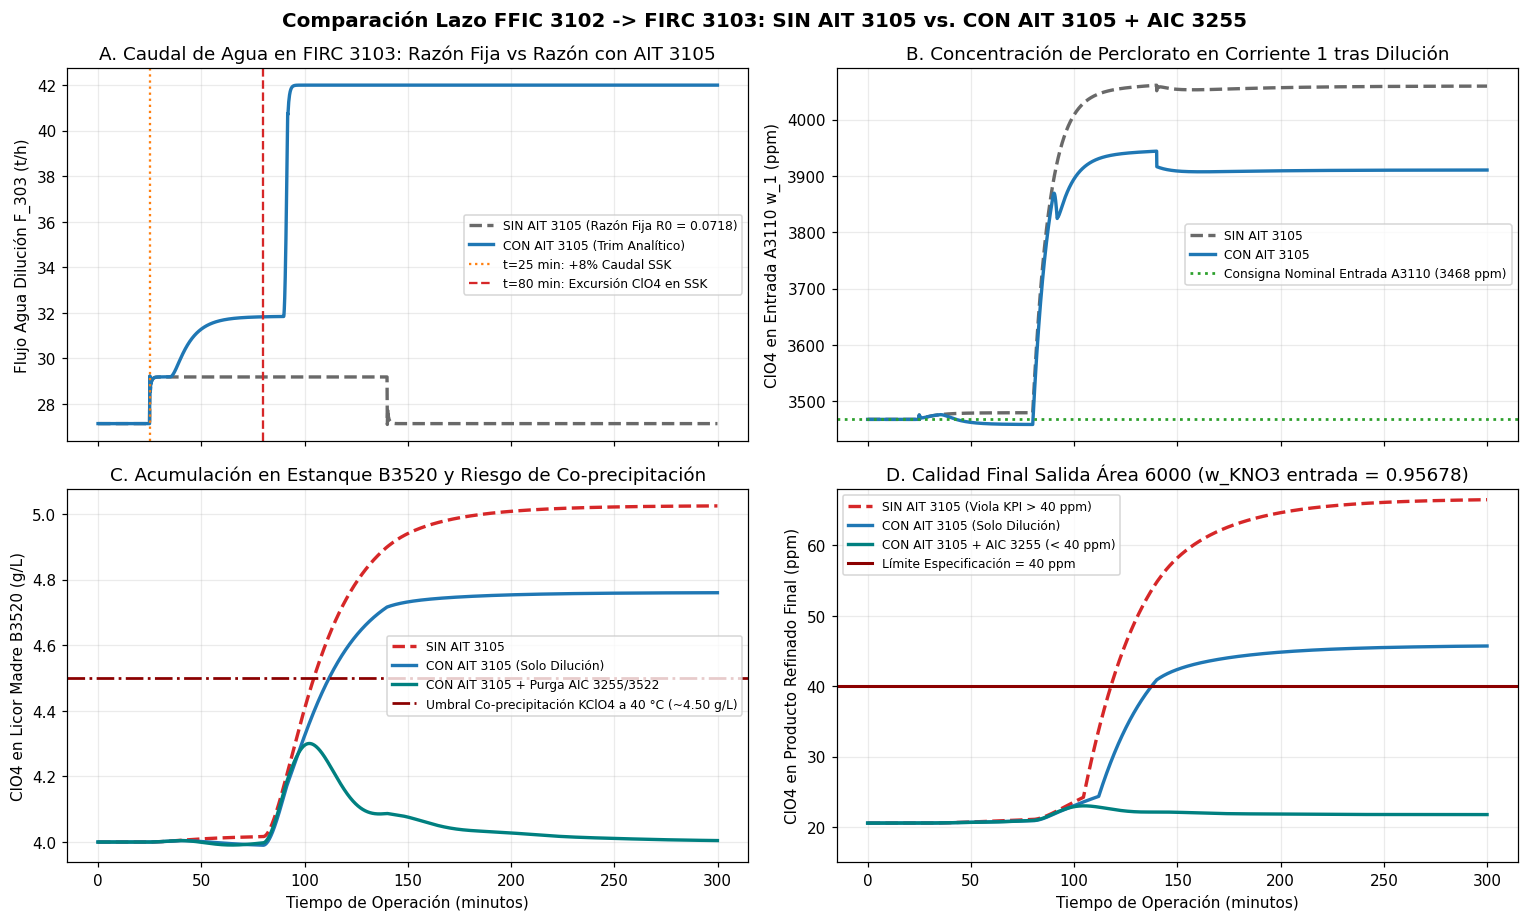

,Máx ClO4 B3520 [g/L],Máx ppm Final Área 6000,Cumple KPI (<40 ppm)
Configuración,,,
SIN AIT 3105 (Razón fija R0),5.02,66.47,NO
CON AIT 3105 (Sin purga activa),4.76,45.70,PARCIAL
CON AIT 3105 + Purga AIC 3255,4.30,23.00,SÍ


In [8]:
# %% [markdown]
# ## B6. Evaluación de Recirculación `B3520 -> A3110` e Impacto del Magnesio ($\\text{Mg}^{2+}$)

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msmpr_core.plant import simulate_plant_npt3_calibrated

df_sin_AIT = simulate_plant_npt3_calibrated(use_AIT3105=False, use_AIC3255=False, tuning_mode="TL_damped")
df_con_AIT = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=False, tuning_mode="TL_damped")
df_con_ambos = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")

fig2, ax2 = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
ax2[0, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["F_303_actual_t_h"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105 (Razón Fija R0 = 0.0718)")
ax2[0, 0].plot(df_con_AIT["t_min"], df_con_AIT["F_303_actual_t_h"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Trim Analítico)")
ax2[0, 0].axvline(25.0, color="tab:orange", ls=":", label="t=25 min: +8% Caudal SSK")
ax2[0, 0].axvline(80.0, color="tab:red", ls="--", label="t=80 min: Excursión ClO4 en SSK")
ax2[0, 0].set_ylabel("Flujo Agua Dilución F_303 (t/h)")
ax2[0, 0].set_title("A. Caudal de Agua en FIRC 3103: Razón Fija vs Razón con AIT 3105")
ax2[0, 0].legend(fontsize=8)

ax2[0, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["w_ClO4_1_ppm"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105")
ax2[0, 1].plot(df_con_AIT["t_min"], df_con_AIT["w_ClO4_1_ppm"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105")
ax2[0, 1].axhline(3468.0, color="tab:green", ls=":", lw=1.8, label="Consigna Nominal Entrada A3110 (3468 ppm)")
ax2[0, 1].set_ylabel("ClO4 en Entrada A3110 w_1 (ppm)")
ax2[0, 1].set_title("B. Concentración de Perclorato en Corriente 1 tras Dilución")
ax2[0, 1].legend(fontsize=8)

ax2[1, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["C_ClO4_B3520_g_L"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105")
ax2[1, 0].plot(df_con_AIT["t_min"], df_con_AIT["C_ClO4_B3520_g_L"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 0].plot(df_con_ambos["t_min"], df_con_ambos["C_ClO4_B3520_g_L"], "-", color="teal", lw=2.2, label="CON AIT 3105 + Purga AIC 3255/3522")
ax2[1, 0].axhline(4.50, color="darkred", ls="-.", lw=1.8, label="Umbral Co-precipitación KClO4 a 40 °C (~4.50 g/L)")
ax2[1, 0].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 0].set_ylabel("ClO4 en Licor Madre B3520 (g/L)")
ax2[1, 0].set_title("C. Acumulación en Estanque B3520 y Riesgo de Co-precipitación")
ax2[1, 0].legend(fontsize=8)

ax2[1, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105 (Viola KPI > 40 ppm)")
ax2[1, 1].plot(df_con_AIT["t_min"], df_con_AIT["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 1].plot(df_con_ambos["t_min"], df_con_ambos["ppm_ClO4_final_6000"], "-", color="teal", lw=2.2, label="CON AIT 3105 + AIC 3255 (< 40 ppm)")
ax2[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación = 40 ppm")
ax2[1, 1].set_ylim(15, 68)
ax2[1, 1].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 1].set_ylabel("ClO4 en Producto Refinado Final (ppm)")
ax2[1, 1].set_title("D. Calidad Final Salida Área 6000 (w_KNO3 entrada = 0.95678)")
ax2[1, 1].legend(fontsize=8)

fig2.suptitle("Comparación Lazo FFIC 3102 -> FIRC 3103: SIN AIT 3105 vs. CON AIT 3105 + AIC 3255", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.savefig("../docs/fig/06_comparacion_FFIC3102_con_sin_AIT3105.png", dpi=220, bbox_inches="tight")
plt.show()

resumen_npt3 = pd.DataFrame([
    {"Configuración": "SIN AIT 3105 (Razón fija R0)", "Máx ClO4 B3520 [g/L]": df_sin_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_sin_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO"},
    {"Configuración": "CON AIT 3105 (Sin purga activa)", "Máx ClO4 B3520 [g/L]": df_con_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "PARCIAL"},
    {"Configuración": "CON AIT 3105 + Purga AIC 3255", "Máx ClO4 B3520 [g/L]": df_con_ambos["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_ambos["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ"},
]).set_index("Configuración")
resumen_npt3.round(2)